In [ ]:
import json
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from collections import defaultdict
from skimage.feature import hog
from sklearn.svm import LinearSVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)
from pathlib import Path
import pandas as pd
import random

Training images: 1741
Training annotations: 2201


In [42]:
# Locate the project root from VS Code's working directory.
PROJECT_DIR = Path.cwd().resolve()

if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

# Use the cleaned dataset to avoid cross-split image overlap.
DATA_DIR = PROJECT_DIR / "data" / "processed"

annotation_path = DATA_DIR / "train" / "_annotations.coco.json"

# Load training annotations for baseline feature extraction.
if not annotation_path.is_file():
    raise FileNotFoundError(
        f"Training annotation file not found: {annotation_path}"
    )

with annotation_path.open("r", encoding="utf-8") as file:
    train_data = json.load(file)

print("Training images:", len(train_data["images"]))
print("Training annotations:", len(train_data["annotations"]))


Training images: 1741
Training annotations: 2201


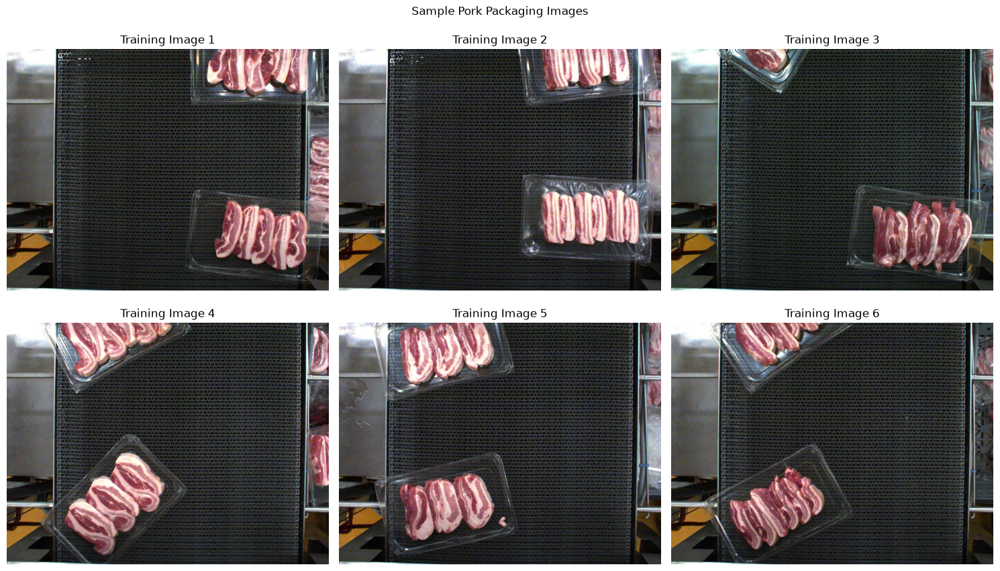

In [ ]:
# Display six training images to inspect packaging appearance and variation.
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for i, ax in enumerate(axes.flat):
    image_info = train_data["images"][i]
    image_path = DATA_DIR / "train" / image_info["file_name"]

    image = cv2.imread(str(image_path))

    if image is None:
        raise FileNotFoundError(image_path)

    # Convert OpenCV's BGR format to RGB for correct visualisation.
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    ax.imshow(image)
    ax.set_title(f"Training Image {i + 1}")
    ax.axis("off")

plt.suptitle("Sample Pork Packaging Images")
plt.tight_layout()
plt.show()

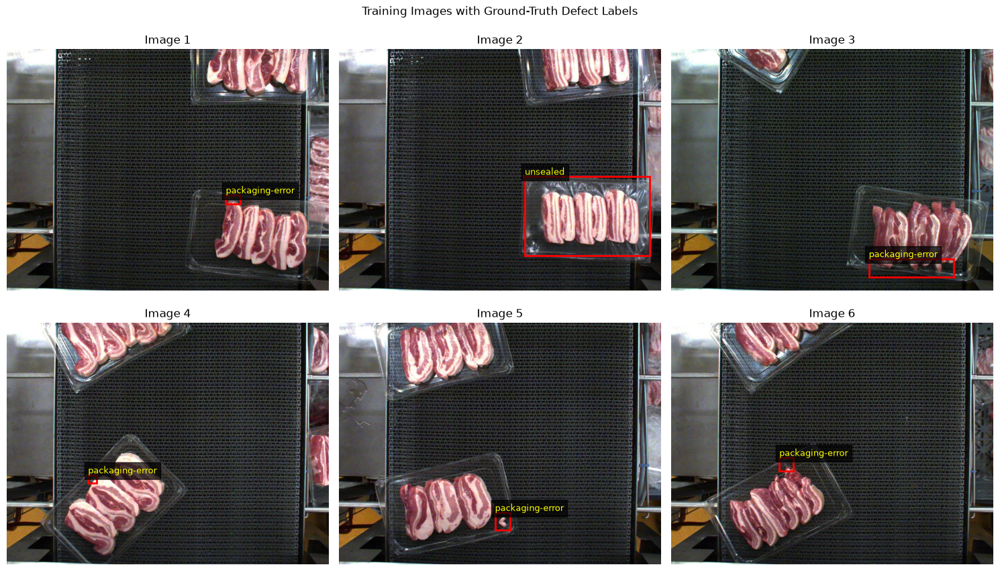

In [ ]:
# Group annotations by image ID for efficient lookup.
annotations_by_image = defaultdict(list)

for ann in train_data["annotations"]:
    annotations_by_image[ann["image_id"]].append(ann)

# Map category IDs to readable defect labels.
category_names = {
    cat["id"]: cat["name"]
    for cat in train_data["categories"]
}

# Display training images with their ground-truth bounding boxes.
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for i, ax in enumerate(axes.flat):
    image_info = train_data["images"][i]
    image_path = DATA_DIR / "train" / image_info["file_name"]

    image = cv2.imread(str(image_path))

    if image is None:
        raise FileNotFoundError(image_path)

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    ax.imshow(image)

    for ann in annotations_by_image[image_info["id"]]:
        # COCO bounding boxes use [x_min, y_min, width, height].
        x, y, w, h = ann["bbox"]
        label = category_names[ann["category_id"]]

        rectangle = plt.Rectangle(
            (x, y),
            w,
            h,
            fill=False,
            edgecolor="red",
            linewidth=2
        )
        ax.add_patch(rectangle)

        # Label each box with its corresponding defect category.
        ax.text(
            x,
            max(0, y - 8),
            label,
            color="yellow",
            fontsize=9,
            bbox=dict(facecolor="black", alpha=0.7)
        )

    ax.set_title(f"Image {i + 1}")
    ax.axis("off")

plt.suptitle("Training Images with Ground-Truth Defect Labels")
plt.tight_layout()
plt.show()

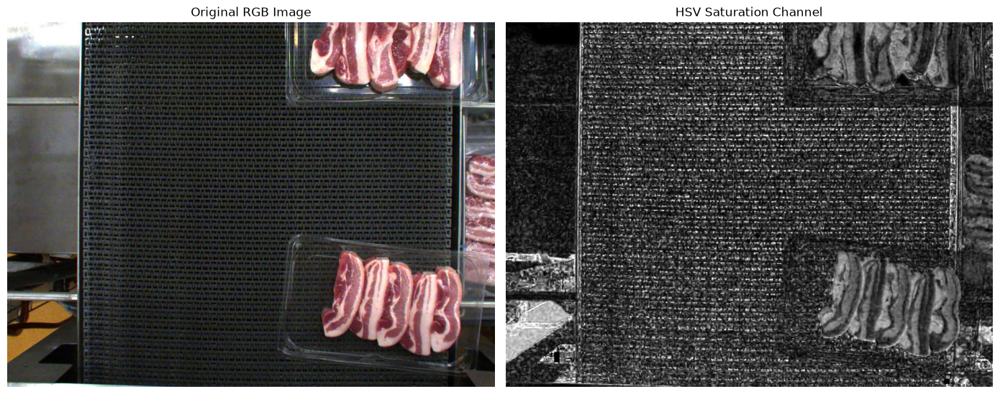

In [5]:
# select a training image
image_info = train_data["images"][0]
image_path = DATA_DIR / "train" / image_info["file_name"]

image = cv2.imread(str(image_path))

if image is None:
    raise FileNotFoundError(image_path)

# Convert image to RGB and HSV
rgb_image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
hsv_image = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

# Display results
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(rgb_image)
axes[0].set_title("Original RGB Image")
axes[0].axis("off")

axes[1].imshow(hsv_image[:, :, 1], cmap="gray")
axes[1].set_title("HSV Saturation Channel")
axes[1].axis("off")

plt.tight_layout()
plt.show()

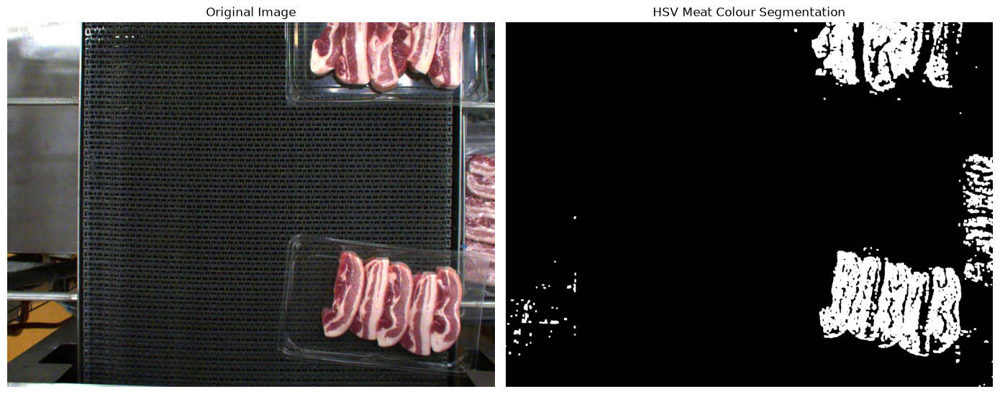

In [6]:
# Initial HSV threshold for reddish meat regions
lower_red1 = np.array([0, 50, 40])
upper_red1 = np.array([15, 255, 255])

lower_red2 = np.array([170, 50, 40])
upper_red2 = np.array([179, 255, 255])

mask1 = cv2.inRange(hsv_image, lower_red1, upper_red1)
mask2 = cv2.inRange(hsv_image, lower_red2, upper_red2)

meat_mask = cv2.bitwise_or(mask1, mask2)

# Remove small noise regions
kernel = np.ones((5, 5), np.uint8)

meat_mask = cv2.morphologyEx(
    meat_mask,
    cv2.MORPH_OPEN,
    kernel
)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(rgb_image)
axes[0].set_title("Original Image")
axes[0].axis("off")

axes[1].imshow(meat_mask, cmap="gray")
axes[1].set_title("HSV Meat Colour Segmentation")
axes[1].axis("off")

plt.tight_layout()
plt.show()

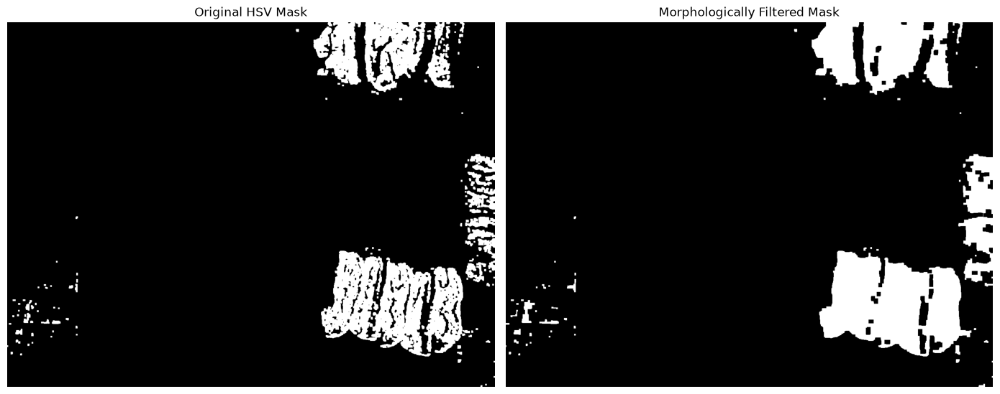

In [ ]:
# Improve segmentation using morphological operations

kernel_close = np.ones((11, 11), np.uint8)

cleaned_mask = cv2.morphologyEx(
    meat_mask,
    cv2.MORPH_CLOSE,
    kernel_close
)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(meat_mask, cmap="gray")
axes[0].set_title("Original HSV Mask")
axes[0].axis("off")

axes[1].imshow(cleaned_mask, cmap="gray")
axes[1].set_title("Morphologically Filtered Mask")
axes[1].axis("off")

plt.tight_layout()
plt.show()

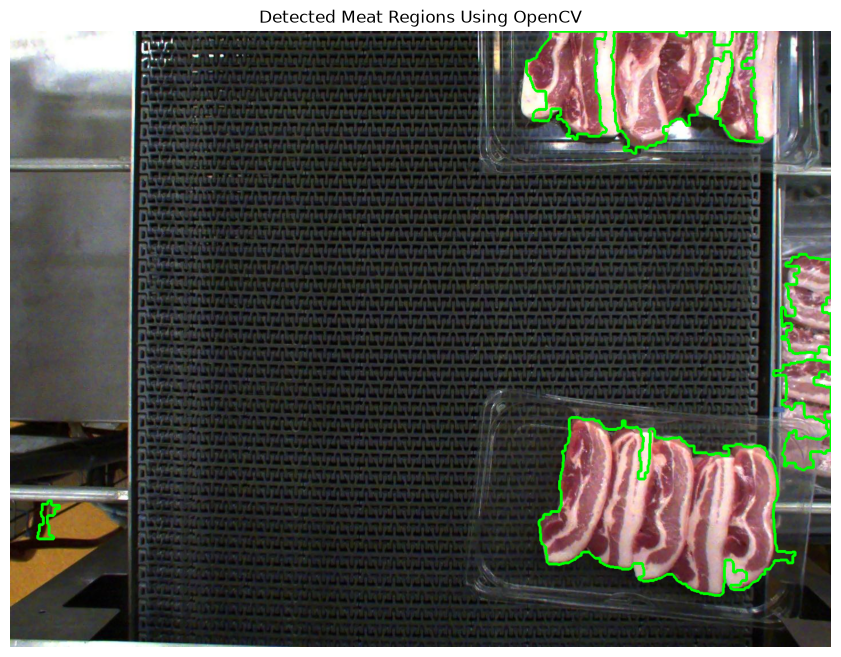

Number of detected regions: 5


In [ ]:
# Detect contours from the filtered mask

contours, _ = cv2.findContours(
    cleaned_mask,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

# Remove very small regions
min_area = 1000

filtered_contours = [
    contour for contour in contours
    if cv2.contourArea(contour) > min_area
]

# Draw contours on the original image
contour_image = rgb_image.copy()

cv2.drawContours(
    contour_image,
    filtered_contours,
    -1,
    (0, 255, 0),
    3
)

plt.figure(figsize=(12, 8))
plt.imshow(contour_image)
plt.title("Detected Meat Regions Using OpenCV")
plt.axis("off")
plt.show()

print("Number of detected regions:", len(filtered_contours))

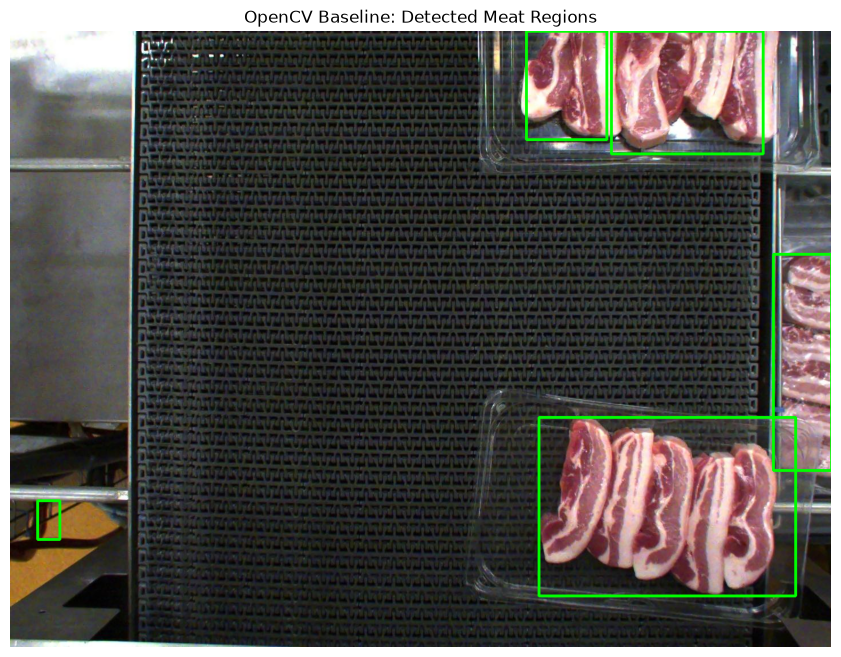

Bounding boxes detected: 5


In [ ]:
# Generate bounding boxes from detected contours

detection_image = rgb_image.copy()

detected_boxes = []

for contour in filtered_contours:

    x, y, w, h = cv2.boundingRect(contour)

    detected_boxes.append([x, y, w, h])

    cv2.rectangle(
        detection_image,
        (x, y),
        (x + w, y + h),
        (0, 255, 0),
        3
    )

plt.figure(figsize=(12, 8))
plt.imshow(detection_image)
plt.title("OpenCV Baseline: Detected Meat Regions")
plt.axis("off")
plt.show()

print("Bounding boxes detected:", len(detected_boxes))

In [ ]:
def detect_meat_regions(image_bgr, min_area=1000):
    """Detect red-coloured meat regions using HSV segmentation.

    Args:
        image_bgr (np.ndarray): Input image in OpenCV BGR format.
        min_area (int, optional): Minimum contour area in pixels.
            Defaults to 1000.

    Returns:
        tuple:
            - boxes (list[tuple]): Detected bounding boxes in
              (x, y, width, height) format.
            - mask (np.ndarray): Binary mask of segmented regions.
    """
    # Convert to HSV for colour-based segmentation.
    hsv = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2HSV)

    # Red occupies two ranges in OpenCV's circular hue scale.
    lower1 = np.array([0, 50, 40])
    upper1 = np.array([15, 255, 255])

    lower2 = np.array([170, 50, 40])
    upper2 = np.array([179, 255, 255])

    mask1 = cv2.inRange(hsv, lower1, upper1)
    mask2 = cv2.inRange(hsv, lower2, upper2)

    mask = cv2.bitwise_or(mask1, mask2)

    # Opening removes small noise; closing fills gaps in meat regions.
    kernel_open = np.ones((5, 5), np.uint8)
    kernel_close = np.ones((11, 11), np.uint8)

    mask = cv2.morphologyEx(
        mask, cv2.MORPH_OPEN, kernel_open
    )

    mask = cv2.morphologyEx(
        mask, cv2.MORPH_CLOSE, kernel_close
    )

    # Extract external contours as candidate meat regions.
    contours, _ = cv2.findContours(
        mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )

    boxes = []

    # Ignore small contours that may represent background noise.
    for contour in contours:
        if cv2.contourArea(contour) > min_area:
            x, y, w, h = cv2.boundingRect(contour)
            boxes.append((x, y, w, h))

    return boxes, mask


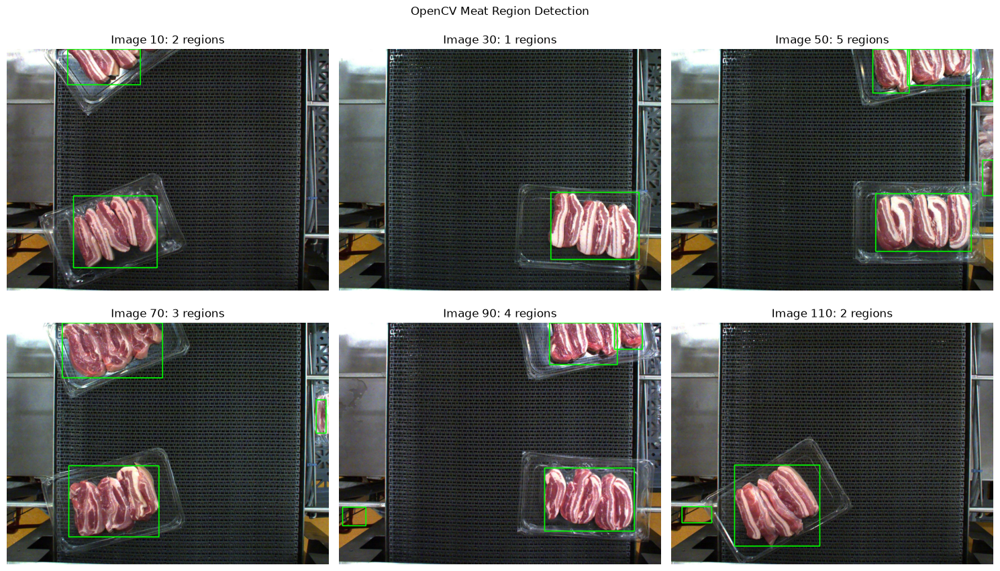

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

sample_indices = [10, 30, 50, 70, 90, 110]

for ax, idx in zip(axes.flat, sample_indices):

    image_info = train_data["images"][idx]

    image_path = (
        DATA_DIR / "train" / image_info["file_name"]
    )

    image_bgr = cv2.imread(str(image_path))

    if image_bgr is None:
        raise FileNotFoundError(image_path)

    boxes, mask = detect_meat_regions(image_bgr)

    image_rgb = cv2.cvtColor(
        image_bgr, cv2.COLOR_BGR2RGB
    )

    for x, y, w, h in boxes:
        cv2.rectangle(
            image_rgb,
            (x, y),
            (x + w, y + h),
            (0, 255, 0),
            3
        )

    ax.imshow(image_rgb)
    ax.set_title(f"Image {idx}: {len(boxes)} regions")
    ax.axis("off")

plt.suptitle("OpenCV Meat Region Detection")
plt.tight_layout()
plt.show()

In [ ]:
def extract_hog(image_bgr):
    """Extract HOG features from an image region.

    Args:
        image_bgr (np.ndarray): Input image in OpenCV BGR format.

    Returns:
        np.ndarray: One-dimensional HOG feature vector containing
            1,764 features.
    """
    # Convert to grayscale and standardise the input to 64 × 64 pixels.
    image = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)
    image = cv2.resize(image, (64, 64))

    # Describe local edge orientations for SVM classification.
    return hog(
        image,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        block_norm="L2-Hys"
    )


print("HOG feature extractor ready.")


HOG feature extractor ready.


In [ ]:
# Fix random seeds to improve reproducibility.
random.seed(42)
np.random.seed(42)


def calculate_iou(box1, box2):
    """Calculate Intersection over Union for two bounding boxes.

    Args:
        box1 (sequence): First box in [x, y, width, height] format.
        box2 (sequence): Second box in [x, y, width, height] format.

    Returns:
        float: IoU between 0 and 1, or 0 if the union is zero.
    """
    x1, y1, w1, h1 = box1
    x2, y2, w2, h2 = box2

    xi1 = max(x1, x2)
    yi1 = max(y1, y2)
    xi2 = min(x1 + w1, x2 + w2)
    yi2 = min(y1 + h1, y2 + h2)

    intersection = max(0, xi2 - xi1) * max(0, yi2 - yi1)
    union = w1 * h1 + w2 * h2 - intersection

    return intersection / union if union > 0 else 0


def is_valid_negative(candidate, annotations):
    """Check whether a candidate region avoids all labelled defects.

    Args:
        candidate (sequence): Region in [x, y, width, height] format.
        annotations (list[dict]): COCO annotations for the image.

    Returns:
        bool: True if the candidate has no intersection with any
        annotated defect; otherwise False.
    """
    x1, y1, w1, h1 = candidate

    for ann in annotations:
        x2, y2, w2, h2 = ann["bbox"]

        intersection_width = max(
            0, min(x1 + w1, x2 + w2) - max(x1, x2)
        )
        intersection_height = max(
            0, min(y1 + h1, y2 + h2) - max(y1, y2)
        )

        # Reject any overlap to avoid treating labelled defects as background.
        if intersection_width * intersection_height > 0:
            return False

    return True


def prepare_training_samples(dataset, image_dir, max_images=500):
    """Generate positive and negative HOG samples for SVM training.

    Args:
        dataset (dict): COCO dataset containing images and annotations.
        image_dir (Path): Directory containing the training images.
        max_images (int): Maximum number of images to process.
            Defaults to 500.

    Returns:
        tuple[np.ndarray, np.ndarray]:
            X: HOG feature matrix, one row per sampled region.
            y: Binary labels (1 = defect, 0 = background).
    """
    X = []
    y = []

    # Index annotations by image ID to avoid repeated full-list searches.
    annotations_by_image = defaultdict(list)

    for ann in dataset["annotations"]:
        annotations_by_image[ann["image_id"]].append(ann)

    for image_info in dataset["images"][:max_images]:
        image_path = image_dir / image_info["file_name"]
        image = cv2.imread(str(image_path))

        if image is None:
            continue

        height, width = image.shape[:2]
        annotations = annotations_by_image[image_info["id"]]

        # Positive samples are crops of ground-truth defect boxes.
        for ann in annotations:
            x, yy, w, h = map(int, ann["bbox"])

            if w <= 0 or h <= 0:
                continue

            crop = image[yy:yy+h, x:x+w]

            if crop.size > 0:
                X.append(extract_hog(crop))
                y.append(1)

        # Sample background regions without intersecting labelled defects.
        for _ in range(max(1, len(annotations))):
            for attempt in range(30):
                w = random.randint(40, min(200, width))
                h = random.randint(40, min(200, height))

                x = random.randint(0, width - w)
                yy = random.randint(0, height - h)

                candidate = [x, yy, w, h]

                if is_valid_negative(candidate, annotations):
                    crop = image[yy:yy+h, x:x+w]

                    if crop.size > 0:
                        X.append(extract_hog(crop))
                        y.append(0)
                        break

    return np.asarray(X), np.asarray(y)


In [ ]:
# Generate HOG features from the first 500 training images.
X_train, y_train = prepare_training_samples(
    train_data,
    DATA_DIR / "train",
    max_images=500
)

# Check feature dimensions and the balance of defect/background samples.
print("Training samples:", len(X_train))
print("HOG features:", X_train.shape[1])

print("Positive samples:", np.sum(y_train == 1))
print("Negative samples:", np.sum(y_train == 0))


Training samples: 1276
HOG features: 1764
Positive samples: 634
Negative samples: 642


In [ ]:
# Standardise HOG features before training the linear SVM.
# Balanced class weights reduce bias from unequal sample counts.
svm_model = make_pipeline(
    StandardScaler(),
    LinearSVC(
        C=1.0,
        class_weight="balanced",
        max_iter=10000,
        random_state=42
    )
)

# Fit the classifier using defect (1) and background (0) samples.
svm_model.fit(X_train, y_train)

print("HOG + SVM baseline model trained successfully!")


HOG + SVM baseline model trained successfully!


In [ ]:
# Load the validation annotations for independent model evaluation.
validation_path = DATA_DIR / "valid" / "_annotations.coco.json"

if not validation_path.is_file():
    raise FileNotFoundError(
        f"Validation annotation file not found: {validation_path}"
    )

with validation_path.open("r", encoding="utf-8") as file:
    valid_data = json.load(file)

# Confirm the validation dataset size.
print("Validation images:", len(valid_data["images"]))
print("Validation annotations:", len(valid_data["annotations"]))


Validation images: 114
Validation annotations: 144


In [ ]:
# Extract positive and negative HOG samples from all validation images.
X_valid, y_valid = prepare_training_samples(
    valid_data,
    DATA_DIR / "valid",
    max_images=len(valid_data["images"])
)

# Check the sample distribution before evaluating the SVM.
print("Validation samples:", len(X_valid))
print("Positive samples:", np.sum(y_valid == 1))
print("Negative samples:", np.sum(y_valid == 0))


Validation samples: 288
Positive samples: 144
Negative samples: 144


Accuracy: 0.8507
Precision: 0.8483
Recall: 0.8542
F1-score: 0.8512

Classification report:
              precision    recall  f1-score   support

  Background       0.85      0.85      0.85       144
      Defect       0.85      0.85      0.85       144

    accuracy                           0.85       288
   macro avg       0.85      0.85      0.85       288
weighted avg       0.85      0.85      0.85       288



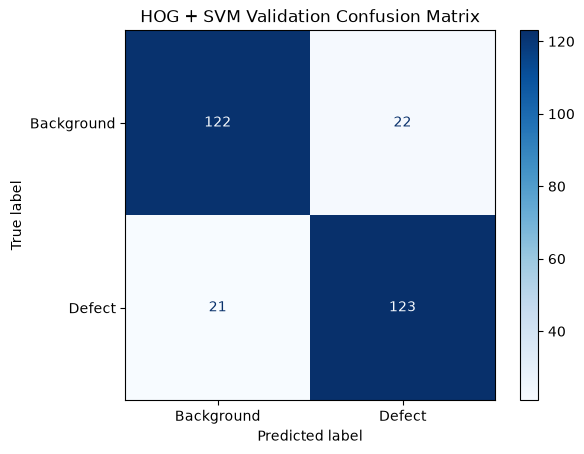

In [ ]:
# Predict validation labels
y_pred = svm_model.predict(X_valid)

print("Accuracy:", round(accuracy_score(y_valid, y_pred), 4))
print("Precision:", round(precision_score(y_valid, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_valid, y_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_valid, y_pred, zero_division=0), 4))

print("\nClassification report:")
print(classification_report(
    y_valid,
    y_pred,
    target_names=["Background", "Defect"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_valid,
    y_pred,
    display_labels=["Background", "Defect"],
    cmap="Blues"
)

plt.title("HOG + SVM Validation Confusion Matrix")
plt.show()

In [ ]:
def intersection_over_candidate(candidate, defect_box):
    """Calculate the proportion of a candidate overlapping a defect.

    Args:
        candidate (sequence): Candidate box in [x, y, width, height].
        defect_box (sequence): Defect box in the same format.

    Returns:
        float: Fraction of the candidate area overlapping the defect,
            between 0 and 1. Returns 0 if the candidate area is zero.
    """
    x1, y1, w1, h1 = candidate
    x2, y2, w2, h2 = defect_box

    # Calculate the intersection between the two bounding boxes.
    xi1 = max(x1, x2)
    yi1 = max(y1, y2)
    xi2 = min(x1 + w1, x2 + w2)
    yi2 = min(y1 + h1, y2 + h2)

    intersection = (
        max(0, xi2 - xi1)
        * max(0, yi2 - yi1)
    )

    candidate_area = w1 * h1

    if candidate_area == 0:
        return 0.0

    return intersection / candidate_area


In [ ]:
MODEL_DIR = PROJECT_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

model_path = MODEL_DIR / "hog_svm_baseline.joblib"

joblib.dump(svm_model, model_path)

print("Model saved to:", model_path)


loaded_model = joblib.load(model_path)

loaded_predictions = loaded_model.predict(X_valid)

print(
    "Predictions match:",
    np.array_equal(y_pred, loaded_predictions)
)

Model saved to: C:\Users\YANG\Desktop\MMA3001\MMA3001-Pork-Packaging-Inspection\models\hog_svm_baseline.joblib
Predictions match: True


In [ ]:
def generate_candidate_regions(
    image, scales=(0.5, 1.0, 1.5), window_size=128, step=64
):
    """Generate multiscale sliding-window candidate regions.

    Args:
        image (np.ndarray): Input image.
        scales (tuple[float, ...]): Window scaling factors.
            Defaults to (0.5, 1.0, 1.5).
        window_size (int): Base window size in pixels.
            Defaults to 128.
        step (int): Sliding-window stride in pixels.
            Defaults to 64.

    Yields:
        tuple[int, int, int, int]: Candidate bounding box in
            (x, y, width, height) format.
    """
    height, width = image.shape[:2]

    # Use multiple window sizes to detect defects at different scales.
    for scale in scales:
        size = int(window_size * scale)

        # Skip windows larger than the input image.
        if size > width or size > height:
            continue

        for y in range(0, height - size + 1, step):
            for x in range(0, width - size + 1, step):
                yield (x, y, size, size)


print("Candidate-region generator ready.")


Candidate-region generator ready.


In [ ]:
def non_maximum_suppression(boxes, scores, iou_threshold=0.3):
    """Remove overlapping boxes using greedy Non-Maximum Suppression.

    Args:
        boxes (list): Bounding boxes in [x, y, width, height] format.
        scores (array-like): SVM decision scores for each box.
        iou_threshold (float): Maximum allowed IoU between
            retained boxes. Defaults to 0.3.

    Returns:
        list[int]: Indices of retained boxes, ordered by
            descending confidence score.
    """
    if len(boxes) == 0:
        return []

    # Process higher-scoring detections first.
    order = np.argsort(scores)[::-1]
    keep = []

    while len(order) > 0:
        i = order[0]
        keep.append(i)

        remaining = []

        # Suppress boxes that overlap too strongly with the selected box.
        for j in order[1:]:
            iou = calculate_iou(boxes[i], boxes[j])

            if iou <= iou_threshold:
                remaining.append(j)

        order = np.array(remaining, dtype=int)

    return keep


print("Non-Maximum Suppression ready.")


Non-Maximum Suppression ready.


In [ ]:
def detect_defects(image_bgr, model, threshold=0.5):
    """Detect defects using a HOG + SVM sliding-window approach.

    Args:
        image_bgr (np.ndarray): Input image in OpenCV BGR format.
        model: Trained HOG + SVM classification pipeline.
        threshold (float): Minimum SVM decision score required
            to retain a detection. Defaults to 0.5.

    Returns:
        tuple:
            - final_boxes (list): Detected bounding boxes in
              [x, y, width, height] format.
            - final_scores (list[float]): Corresponding SVM
              decision scores after Non-Maximum Suppression.
    """
    # Generate multiscale regions for full-image defect detection.
    candidate_boxes = list(generate_candidate_regions(image_bgr))

    if not candidate_boxes:
        return [], []

    features = []

    # Extract HOG features from each candidate region.
    for x, y, w, h in candidate_boxes:
        crop = image_bgr[y:y+h, x:x+w]
        features.append(extract_hog(crop))

    features = np.asarray(features)

    # SVM decision scores are margins, not calibrated probabilities.
    scores = model.decision_function(features)

    # Retain regions exceeding the selected decision threshold.
    selected = np.where(scores > threshold)[0]

    boxes = [candidate_boxes[i] for i in selected]
    selected_scores = [float(scores[i]) for i in selected]

    # Remove overlapping detections to reduce duplicate predictions.
    keep = non_maximum_suppression(
        boxes, selected_scores, iou_threshold=0.3
    )

    final_boxes = [boxes[i] for i in keep]
    final_scores = [selected_scores[i] for i in keep]

    return final_boxes, final_scores


print("Full-image baseline detector ready.")


Full-image baseline detector ready.


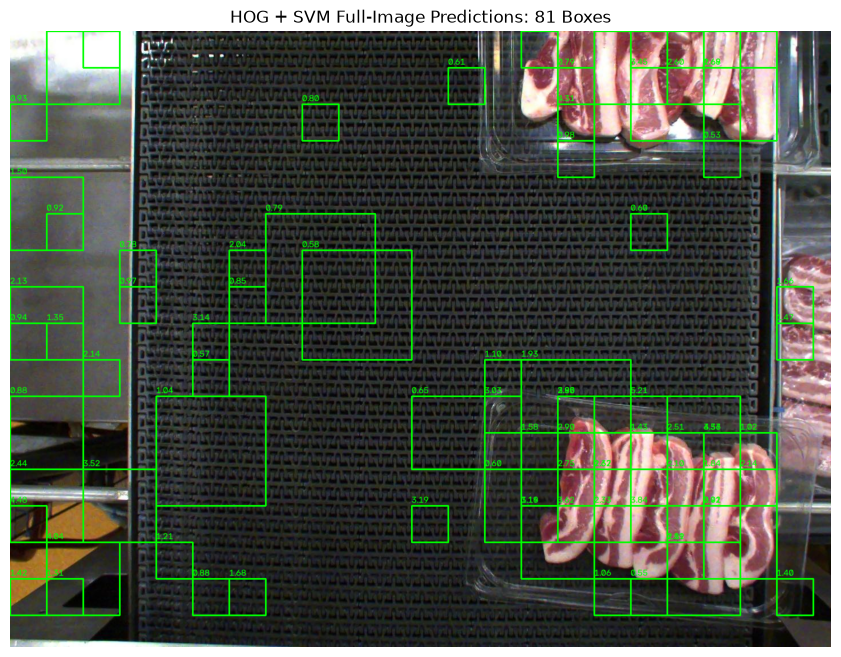

Detected candidate defects: 81


In [ ]:
# Select a training image to inspect full-image detection results.
image_info = train_data["images"][0]
image_path = DATA_DIR / "train" / image_info["file_name"]

image_bgr = cv2.imread(str(image_path))

if image_bgr is None:
    raise FileNotFoundError(image_path)

# Detect candidate defects using the saved SVM model.
boxes, scores = detect_defects(image_bgr, loaded_model)

# Convert to RGB for Matplotlib visualisation.
result = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

for (x, y, w, h), score in zip(boxes, scores):
    # Draw each predicted box and its SVM decision score.
    cv2.rectangle(
        result, (x, y), (x + w, y + h), (0, 255, 0), 2
    )

    cv2.putText(
        result,
        f"{score:.2f}",
        (x, max(y - 5, 0)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.5,
        (0, 255, 0),
        1
    )

plt.figure(figsize=(12, 8))
plt.imshow(result)
plt.title(f"HOG + SVM Full-Image Predictions: {len(boxes)} Boxes")
plt.axis("off")
plt.show()

print("Detected candidate defects:", len(boxes))

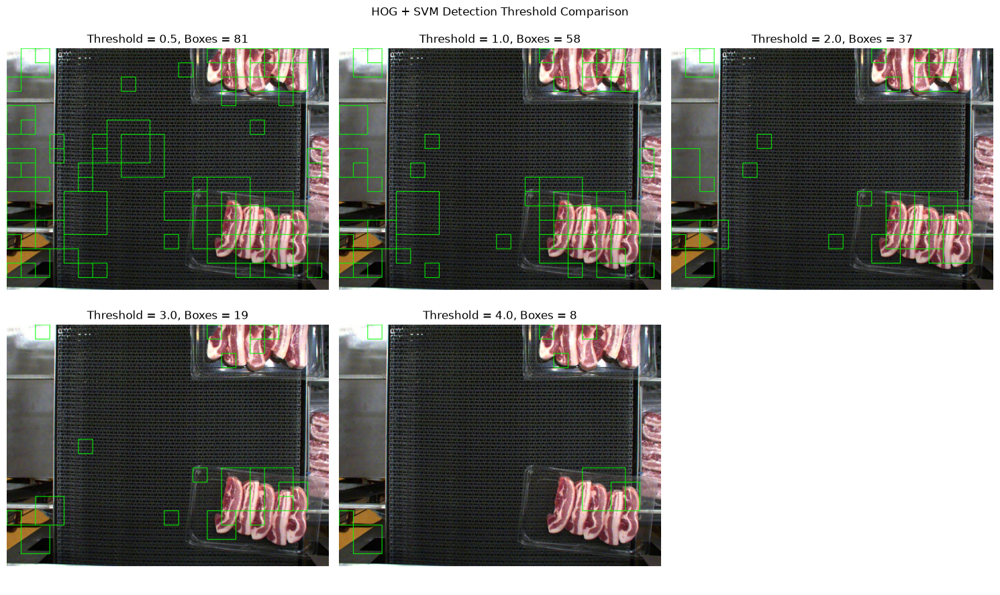

,Threshold,Detected Boxes
0,0.5,81
1,1.0,58
2,2.0,37
3,3.0,19
4,4.0,8


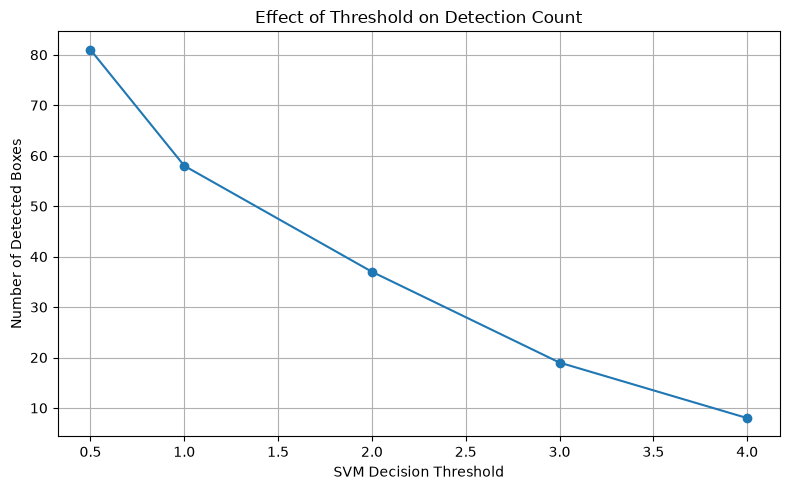

In [ ]:
# Compare how SVM decision thresholds affect the detection count.
thresholds = [0.5, 1.0, 2.0, 3.0, 4.0]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

results = []

for ax, threshold in zip(axes.flat, thresholds):

    boxes, scores = detect_defects(
        image_bgr,
        loaded_model,
        threshold=threshold
    )

    result_image = cv2.cvtColor(
        image_bgr.copy(),
        cv2.COLOR_BGR2RGB
    )

    # Visualise the detections remaining at each threshold.
    for x, y, w, h in boxes:
        cv2.rectangle(
            result_image,
            (x, y),
            (x + w, y + h),
            (0, 255, 0),
            2
        )

    ax.imshow(result_image)
    ax.set_title(
        f"Threshold = {threshold}, Boxes = {len(boxes)}"
    )
    ax.axis("off")

    results.append({
        "Threshold": threshold,
        "Detected Boxes": len(boxes)
    })

# Hide the unused sixth subplot.
axes.flat[-1].axis("off")

plt.suptitle("HOG + SVM Detection Threshold Comparison")
plt.tight_layout()
plt.show()

# Summarise the sensitivity of detection count to threshold selection.
threshold_df = pd.DataFrame(results)
display(threshold_df)

plt.figure(figsize=(8, 5))
plt.plot(
    threshold_df["Threshold"],
    threshold_df["Detected Boxes"],
    marker="o"
)

plt.xlabel("SVM Decision Threshold")
plt.ylabel("Number of Detected Boxes")
plt.title("Effect of Threshold on Detection Count")
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
def evaluate_image_detection(
    pred_boxes, pred_scores, gt_boxes, iou_threshold=0.5
):
    """Evaluate predicted bounding boxes against ground truth.

    Each ground-truth box can be matched to only one prediction.

    Args:
        pred_boxes (list): Predicted boxes in [x, y, width, height].
        pred_scores (array-like): SVM decision scores for each box.
        gt_boxes (list): Ground-truth boxes in the same format.
        iou_threshold (float): Minimum IoU for a correct detection.
            Defaults to 0.5.

    Returns:
        tuple[int, int, int]: Counts of true positives (TP),
            false positives (FP), and false negatives (FN).
    """
    matched_gt = set()
    tp = 0
    fp = 0

    # Match higher-scoring predictions first.
    order = np.argsort(pred_scores)[::-1]

    for i in order:
        pred = pred_boxes[i]

        best_iou = 0
        best_gt = -1

        # Find the best unmatched ground-truth box.
        for j, gt in enumerate(gt_boxes):
            if j in matched_gt:
                continue

            iou = calculate_iou(pred, gt)

            if iou > best_iou:
                best_iou = iou
                best_gt = j

        # Count each ground-truth defect at most once.
        if best_iou >= iou_threshold and best_gt >= 0:
            tp += 1
            matched_gt.add(best_gt)
        else:
            fp += 1

    # Ground-truth defects without a match are false negatives.
    fn = len(gt_boxes) - len(matched_gt)

    return tp, fp, fn

In [ ]:
# Group validation annotations by image ID for efficient lookup.
valid_annotations = defaultdict(list)

for ann in valid_data["annotations"]:
    valid_annotations[ann["image_id"]].append(ann)

# Evaluate the detector at different SVM decision thresholds.
thresholds = [0.5, 1.0, 2.0, 3.0, 4.0]
validation_results = []

# Limit this preliminary evaluation to 20 validation images.
validation_images = valid_data["images"][:20]

for threshold in thresholds:
    total_tp = 0
    total_fp = 0
    total_fn = 0

    for image_info in validation_images:
        image_path = DATA_DIR / "valid" / image_info["file_name"]

        image = cv2.imread(str(image_path))

        if image is None:
            raise FileNotFoundError(image_path)

        # Detect candidate defects using the selected threshold.
        pred_boxes, pred_scores = detect_defects(
            image,
            loaded_model,
            threshold=threshold
        )

        gt_boxes = [
            ann["bbox"]
            for ann in valid_annotations[image_info["id"]]
        ]

        # Match predictions to ground truth at IoU >= 0.50.
        tp, fp, fn = evaluate_image_detection(
            pred_boxes,
            pred_scores,
            gt_boxes,
            iou_threshold=0.5
        )

        total_tp += tp
        total_fp += fp
        total_fn += fn

    # Calculate detection precision, recall and F1-score.
    precision = (
        total_tp / (total_tp + total_fp)
        if total_tp + total_fp > 0 else 0
    )

    recall = (
        total_tp / (total_tp + total_fn)
        if total_tp + total_fn > 0 else 0
    )

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall > 0 else 0
    )

    validation_results.append({
        "Threshold": threshold,
        "TP": total_tp,
        "FP": total_fp,
        "FN": total_fn,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1
    })

# Summarise the detection performance at each threshold.
validation_df = pd.DataFrame(validation_results)

display(validation_df)

,Threshold,TP,FP,FN,Precision,Recall,F1-score
0,0.5,2,2019,30,0.000990,0.06250,0.001948
1,1.0,2,1429,30,0.001398,0.06250,0.002734
2,2.0,2,696,30,0.002865,0.06250,0.005479
3,3.0,1,311,31,0.003205,0.03125,0.005814
4,4.0,1,135,31,0.007353,0.03125,0.011905
